# Part B: Predictors (expected consumption)

**What this notebook does, in order**
1. Loads the raw electricity readings for the 200 labeled buildings, converts to kWh, and builds a complete hourly table (every building, every hour of 2016).
2. Marks long runs of zeros as missing (the same rule as Part A).
3. Adds weather (carried forward only, never backward).
4. Builds features: calendar, building facts, weather, and **history** (same hour yesterday, same hour last week, previous hour). History is taken from the hourly table by time, and a check confirms it.
5. Builds the two simple predictors: **same as last hour** and **historical typical value**.
6. Trains one tree model on three feature sets: **A** (no history), **B** (adds yesterday and last week), **C** (adds the previous hour). All three use identical settings and the same training rows.
7. Saves the predictions and an accuracy table.

**What this notebook does not do:** it does not use labels, and it does not flag anything. Flagging is Part C.

**Fairness rules built in**
- The split is by time: train before 2016-09-13, validation until 2016-11-07, test after. The month is not used as a feature, because training covers only January to September.
- Everything learned (typical values, model) comes from the training period. Settings are chosen on validation only.
- All models train on the same rows, those where all history values exist, so A, B and C differ only in the features they see.
- A model's prediction is left empty on hours where its own history is missing. Part C then compares predictors on exactly the same hours.

Run the cells in order. Cells marked **CHANGE** may need your paths. Expect roughly 10 to 20 minutes in total on a laptop; the tuning step is the slow part and can be switched off.

## 0. Settings (CHANGE)

In [1]:
from pathlib import Path
import json, time
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor

# ---- paths (relative to the folder this notebook is in) ----
GEPIII_TRAIN = "ashrae-energy-prediction/train.csv"
GEPIII_META  = "ashrae-energy-prediction/building_metadata.csv"
GEPIII_WEATHER = "ashrae-energy-prediction/weather_train.csv"
LABELED_IDS  = "outputs/labeled_building_ids.csv"     # from Part A
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ---- time split (same as Parts A, C, D) ----
GRID_START = pd.Timestamp("2016-01-01 00:00")
GRID_END   = pd.Timestamp("2016-12-31 23:00")
TRAIN_END  = pd.Timestamp("2016-09-13")
VAL_END    = pd.Timestamp("2016-11-07")

# ---- data rules ----
ZERO_RUN_HOURS = 24            # a run of exact zeros this long is treated as missing
CONVERT_SITE0_TO_KWH = True    # site 0 is stored in kBTU in GEPIII
KBTU_TO_KWH = 0.2931

# ---- model settings ----
TUNE = True                    # try a few settings on validation and keep the best (set False to save time)
TUNE_SAMPLE = 0.3              # share of training rows used while tuning
DEFAULT_PARAMS = dict(max_iter=300, learning_rate=0.1, max_leaf_nodes=63, min_samples_leaf=50, l2_regularization=0.0)
CANDIDATES = [
    dict(max_iter=200, learning_rate=0.1,  max_leaf_nodes=31,  min_samples_leaf=50, l2_regularization=0.0),
    dict(max_iter=400, learning_rate=0.1,  max_leaf_nodes=63,  min_samples_leaf=50, l2_regularization=0.0),
    dict(max_iter=600, learning_rate=0.05, max_leaf_nodes=127, min_samples_leaf=100, l2_regularization=1.0),
]
SEED = 0

## 1. Load the readings and build the hourly table

**What happens:** only electricity (meter 0) for the 200 labeled buildings is read, in chunks to save memory. Site 0 is converted from kBTU to kWh. Then a complete table is built: every building crossed with every hour of 2016. Hours with no reading become empty values, and are never invented.

**What to check:** 200 buildings, 8,784 hours each, 1,756,800 rows, and a small share of empty readings.

In [2]:
ids = pd.read_csv(LABELED_IDS)["building_id"].astype(int).tolist()
id_set = set(ids)

parts = []
for chunk in pd.read_csv(GEPIII_TRAIN, usecols=["building_id", "meter", "timestamp", "meter_reading"],
                         dtype={"building_id": "int32", "meter": "int8", "meter_reading": "float32"},
                         chunksize=2_000_000):
    chunk = chunk[(chunk["meter"] == 0) & chunk["building_id"].isin(id_set)]
    parts.append(chunk.drop(columns="meter"))
raw = pd.concat(parts, ignore_index=True)
raw["timestamp"] = pd.to_datetime(raw["timestamp"])
raw = raw.drop_duplicates(["building_id", "timestamp"])

meta = pd.read_csv(GEPIII_META)
meta = meta[meta["building_id"].isin(id_set)].copy()
raw = raw.merge(meta[["building_id", "site_id"]], on="building_id", how="left")
if CONVERT_SITE0_TO_KWH:
    is0 = raw["site_id"].eq(0)
    raw.loc[is0, "meter_reading"] = (raw.loc[is0, "meter_reading"] * KBTU_TO_KWH).astype("float32")
    print("converted", int(is0.sum()), "rows at site 0 from kBTU to kWh")

hours = pd.date_range(GRID_START, GRID_END, freq="h")
grid = pd.MultiIndex.from_product([sorted(id_set), hours], names=["building_id", "timestamp"]).to_frame(index=False)
df = grid.merge(raw[["building_id", "timestamp", "meter_reading"]], on=["building_id", "timestamp"], how="left")
df = df.sort_values(["building_id", "timestamp"]).reset_index(drop=True)

print("buildings:", df["building_id"].nunique(), "| hours per building:", df.groupby("building_id").size().unique())
print("rows:", len(df), "| empty readings:", int(df["meter_reading"].isna().sum()),
      f"({df['meter_reading'].isna().mean()*100:.2f}%)")

converted 70272 rows at site 0 from kBTU to kWh
buildings: 200 | hours per building: [8784]
rows: 1756800 | empty readings: 7306 (0.42%)


## 2. Mark long zero runs as missing

**What happens:** a run of exact zeros lasting `ZERO_RUN_HOURS` hours or more is treated as missing (a meter or data problem, not real low use). This is the same rule as Part A, so the hours match. The cleaned reading `y` is used for training and history; the original reading is kept for the output file.

In [3]:
z = df["meter_reading"].eq(0)
change = (z != z.shift()) | (df["building_id"] != df["building_id"].shift())
run_id = change.cumsum()
run_len = z.groupby(run_id).transform("size")
df["in_zero_run"] = z & (run_len >= ZERO_RUN_HOURS)
df["y"] = df["meter_reading"].where(~df["in_zero_run"])

print("hours in zero runs:", int(df["in_zero_run"].sum()), f"({df['in_zero_run'].mean()*100:.2f}% of rows)")
print("usable readings (not empty, not in a zero run):", int(df["y"].notna().sum()))

hours in zero runs: 54095 (3.08% of rows)
usable readings (not empty, not in a zero run): 1695399


## 3. Add weather and building facts

**What happens:** weather is placed on the hourly grid for each site and carried **forward only**. A missing value is filled with the last known earlier value, never a later one, so no future information leaks backward. Values still missing at the very start stay empty (the model handles empty values). Building facts are joined by building.

The calendar month is deliberately not used.

In [4]:
wcols = ["air_temperature", "dew_temperature", "cloud_coverage", "precip_depth_1_hr", "sea_level_pressure", "wind_speed"]
w = pd.read_csv(GEPIII_WEATHER, usecols=["site_id", "timestamp"] + wcols, parse_dates=["timestamp"])
sites = sorted(meta["site_id"].unique())
w = w[w["site_id"].isin(sites)].drop_duplicates(["site_id", "timestamp"])
wgrid = pd.MultiIndex.from_product([sites, hours], names=["site_id", "timestamp"])
w = w.set_index(["site_id", "timestamp"]).reindex(wgrid)
w = w.groupby(level="site_id").ffill().reset_index()          # forward fill only

df = df.merge(meta[["building_id", "site_id", "primary_use", "square_feet", "year_built", "floor_count"]],
              on="building_id", how="left").merge(w, on=["site_id", "timestamp"], how="left")

use_codes = {u: i for i, u in enumerate(sorted(meta["primary_use"].unique()))}
df["primary_use_code"] = df["primary_use"].map(use_codes)
df["bld_idx"] = df["building_id"].map({b: i for i, b in enumerate(sorted(id_set))})
df["hour"] = df["timestamp"].dt.hour
df["dow"] = df["timestamp"].dt.dayofweek
df["is_weekend"] = (df["dow"] >= 5).astype(int)
df["split"] = np.where(df["timestamp"] < TRAIN_END, "train", np.where(df["timestamp"] < VAL_END, "val", "test"))

print("share still empty per weather column:")
print(df[wcols].isna().mean().round(3).to_string())
print("rows per split:", df["split"].value_counts().to_dict())

share still empty per weather column:
air_temperature       0.000
dew_temperature       0.000
cloud_coverage        0.005
precip_depth_1_hr     0.205
sea_level_pressure    0.120
wind_speed            0.000
rows per split: {'train': 1228800, 'val': 264000, 'test': 264000}


## 4. History features (by time) and a check

**What happens:** the table has exactly one row per building per hour, so a shift of 1, 24 or 168 rows is the reading 1 hour, 1 day or 1 week earlier. History values are on the log scale, `log(1 + kWh)`, built from the cleaned reading, so zero-run hours and missing hours give empty history.

**Check:** the notebook looks the history up again by time (timestamp minus 24 hours) and compares. All values must match. If not, stop and fix before going on.

In [5]:
df["ly"] = np.log1p(df["y"])
g = df.groupby("building_id")["ly"]
df["lag_1"] = g.shift(1)
df["lag_24"] = g.shift(24)
df["lag_168"] = g.shift(168)

# check: look up the reading 24 h and 168 h earlier by timestamp and compare
look = df[["building_id", "timestamp", "ly"]].copy()
for k in (24, 168):
    shifted = look.assign(timestamp=look["timestamp"] + pd.Timedelta(hours=k)).rename(columns={"ly": f"chk_{k}"})
    m = df[["building_id", "timestamp", f"lag_{k}"]].merge(shifted[["building_id", "timestamp", f"chk_{k}"]],
                                                           on=["building_id", "timestamp"], how="left")
    same = np.isclose(m[f"lag_{k}"], m[f"chk_{k}"], equal_nan=True)
    print(f"lag_{k}: matches the time-based lookup on {same.mean()*100:.3f}% of rows")
    assert same.all(), f"lag_{k} does not match a time-based lookup"

df["common"] = df[["lag_1", "lag_24", "lag_168"]].notna().all(axis=1) & df["y"].notna()
print()
print("rows with all history present and a usable reading, per split:")
print(df[df["common"]].groupby("split").size().reindex(["train", "val", "test"]).to_string())

lag_24: matches the time-based lookup on 100.000% of rows
lag_168: matches the time-based lookup on 100.000% of rows

rows with all history present and a usable reading, per split:
split
train    1135206
val       249407
test      257993


## 5. The two simple predictors

**Same as last hour.** The prediction for an hour is the previous hour's reading (kWh). It needs no training and sets the bar that any model has to beat. It is empty where the previous hour is missing.

**Historical typical value.** The median reading for the same building, same hour of day, and weekday-or-weekend, using the **training period only**. If a combination has no data it falls back to the building and hour, then to the building.

In [6]:
df["pred_last_hour"] = df.groupby("building_id")["y"].shift(1)

tr = df[(df["split"] == "train") & df["y"].notna()]
med3 = tr.groupby(["building_id", "hour", "is_weekend"])["y"].median().rename("m3")
med2 = tr.groupby(["building_id", "hour"])["y"].median().rename("m2")
med1 = tr.groupby("building_id")["y"].median().rename("m1")
df = (df.merge(med3, left_on=["building_id", "hour", "is_weekend"], right_index=True, how="left")
        .merge(med2, left_on=["building_id", "hour"], right_index=True, how="left")
        .merge(med1, left_on="building_id", right_index=True, how="left"))
df["pred_typical"] = df["m3"].fillna(df["m2"]).fillna(df["m1"])
df = df.drop(columns=["m3", "m2", "m1"])
df = df.sort_values(["building_id", "timestamp"]).reset_index(drop=True)

print("empty same-as-last-hour predictions:", int(df["pred_last_hour"].isna().sum()))
print("empty typical-value predictions:", int(df["pred_typical"].isna().sum()))

empty same-as-last-hour predictions: 61598
empty typical-value predictions: 0


## 6. The model: feature sets A, B and C

**What happens:** one tree model (histogram gradient boosting) is trained on the log of the reading. Three feature sets are used:
- **A:** calendar, building facts, weather (no history),
- **B:** A plus same hour yesterday and same hour last week,
- **C:** B plus the previous hour.

Building and use type are treated as categories. All three models use identical settings and the same training rows (rows where all history exists), so the only difference is what each one is allowed to see.

In [7]:
cal = ["hour", "dow", "is_weekend"]
bld = ["bld_idx", "site_id", "primary_use_code", "square_feet", "year_built", "floor_count"]
cat_cols = ["bld_idx", "site_id", "primary_use_code"]
FEATURES = {
    "A": cal + bld + wcols,
    "B": cal + bld + wcols + ["lag_24", "lag_168"],
    "C": cal + bld + wcols + ["lag_24", "lag_168", "lag_1"],
}
# a feature that is empty for every training row cannot be used (and would stop the model), so drop it
_train = df[df["split"] == "train"]
empty_feats = [c for c in dict.fromkeys(sum(FEATURES.values(), [])) if _train[c].isna().all()]
if empty_feats:
    print("dropping features that are empty in the training period:", empty_feats)
    FEATURES = {k: [c for c in v if c not in empty_feats] for k, v in FEATURES.items()}
for k, v in FEATURES.items():
    print(k, len(v), "features")

train_rows = df[(df["split"] == "train") & df["common"]]
val_rows = df[(df["split"] == "val") & df["common"]]
print("training rows:", len(train_rows), "| validation rows:", len(val_rows))

def make_model(params):
    return HistGradientBoostingRegressor(loss="squared_error", early_stopping=False, random_state=SEED, **params)

def fit(feats, params, rows):
    mask = [c in cat_cols for c in feats]
    m = make_model(params)
    m.set_params(categorical_features=mask)
    m.fit(rows[feats], np.log1p(rows["y"]))
    return m

def rmsle(model, feats, rows):
    p = model.predict(rows[feats])
    return float(np.sqrt(np.mean((p - np.log1p(rows["y"])) ** 2)))

A 15 features
B 17 features
C 18 features
training rows: 1135206 | validation rows: 249407


## 7. Light tuning (validation only, feature set C)

**What happens:** three settings are tried on a sample of the training rows, using set C. The one with the lowest validation error is used for **all three** feature sets. Tuning uses validation only, never test. Set `TUNE = False` to skip this and use the default settings.

In [8]:
if TUNE:
    sample = train_rows.sample(frac=TUNE_SAMPLE, random_state=SEED)
    results = []
    for p in CANDIDATES:
        t0 = time.time()
        m = fit(FEATURES["C"], p, sample)
        e = rmsle(m, FEATURES["C"], val_rows)
        results.append((e, p))
        print(f"validation error {e:.4f} | {p} | {time.time()-t0:.0f}s")
    BEST = min(results, key=lambda r: r[0])[1]
else:
    BEST = DEFAULT_PARAMS
print("\nsettings used for A, B and C:", BEST)

validation error 0.1864 | {'max_iter': 200, 'learning_rate': 0.1, 'max_leaf_nodes': 31, 'min_samples_leaf': 50, 'l2_regularization': 0.0} | 3s
validation error 0.1878 | {'max_iter': 400, 'learning_rate': 0.1, 'max_leaf_nodes': 63, 'min_samples_leaf': 50, 'l2_regularization': 0.0} | 8s
validation error 0.1838 | {'max_iter': 600, 'learning_rate': 0.05, 'max_leaf_nodes': 127, 'min_samples_leaf': 100, 'l2_regularization': 1.0} | 16s

settings used for A, B and C: {'max_iter': 600, 'learning_rate': 0.05, 'max_leaf_nodes': 127, 'min_samples_leaf': 100, 'l2_regularization': 1.0}


## 8. Train A, B and C and predict every hour

**What happens:** each feature set is trained on the full training rows with the chosen settings, then predicts every hour. Predictions are converted back to kWh. A model's prediction is left **empty** where its own history is missing, so Part C compares predictors on identical hours.

In [9]:
models = {}
for name, feats in FEATURES.items():
    t0 = time.time()
    models[name] = fit(feats, BEST, train_rows)
    p = np.expm1(models[name].predict(df[feats])).clip(min=0)
    df["pred_" + name] = p
    print(f"model {name} trained in {time.time()-t0:.0f}s")

df.loc[df[["lag_24", "lag_168"]].isna().any(axis=1), "pred_B"] = np.nan
df.loc[df[["lag_1", "lag_24", "lag_168"]].isna().any(axis=1), "pred_C"] = np.nan
print("empty predictions  A:", int(df["pred_A"].isna().sum()), "| B:", int(df["pred_B"].isna().sum()),
      "| C:", int(df["pred_C"].isna().sum()))

model A trained in 27s
model B trained in 29s
model C trained in 31s
empty predictions  A: 0 | B: 106951 | C: 113160


## 9. Accuracy of the predictors

**What happens:** all five predictors are scored on the same hours (reading usable, every prediction present), for validation and test. Measures: mean absolute error and root mean squared error in kWh, R squared, and the error on the log scale (RMSLE).

**This is a check on the predictors, not the project result.** The project result is how well the flags match the labeled events (Part D). Accuracy and flag quality can disagree.

**What to expect:** the models should beat the typical value, and C should be the most accurate and A the least. If B and C look as good as your old model (R squared about 0.968), that is believable only for C. A and B should score lower, because the old pipeline used information that is not allowed here. If A is as good as C, check for leakage.

In [10]:
pc = ["pred_last_hour", "pred_typical", "pred_A", "pred_B", "pred_C"]
names = {"pred_last_hour": "Same as last hour", "pred_typical": "Historical typical value",
         "pred_A": "Model A (no history)", "pred_B": "Model B (+ yesterday, last week)", "pred_C": "Model C (+ previous hour)"}
rows = []
for sp in ["val", "test"]:
    d = df[(df["split"] == sp) & df["y"].notna() & df[pc].notna().all(axis=1)]
    for c in pc:
        err = d["y"] - d[c]
        ss_res = float((err ** 2).sum())
        ss_tot = float(((d["y"] - d["y"].mean()) ** 2).sum())
        rows.append({"split": sp, "predictor": names[c], "hours": len(d),
                     "MAE_kWh": err.abs().mean(), "RMSE_kWh": np.sqrt((err ** 2).mean()),
                     "R2": 1 - ss_res / ss_tot,
                     "RMSLE": np.sqrt(((np.log1p(d["y"]) - np.log1p(d[c].clip(lower=0))) ** 2).mean())})
acc = pd.DataFrame(rows)
acc.round({"MAE_kWh": 2, "RMSE_kWh": 2, "R2": 3, "RMSLE": 3}).to_csv(OUT_DIR / "predictor_accuracy.csv", index=False)
print(acc.round({"MAE_kWh": 2, "RMSE_kWh": 2, "R2": 3, "RMSLE": 3}).to_string(index=False))

split                        predictor  hours  MAE_kWh  RMSE_kWh    R2  RMSLE
  val                Same as last hour 249407     9.10     49.09 0.984  0.234
  val         Historical typical value 249407    23.18     65.28 0.971  0.753
  val             Model A (no history) 249407    26.03     67.90 0.969  0.698
  val Model B (+ yesterday, last week) 249407    16.41     55.92 0.979  0.518
  val        Model C (+ previous hour) 249407     8.21     33.39 0.992  0.178
 test                Same as last hour 257993     8.09     30.45 0.993  0.200
 test         Historical typical value 257993    30.28     77.00 0.958  0.699
 test             Model A (no history) 257993    32.71     79.20 0.955  0.705
 test Model B (+ yesterday, last week) 257993    19.62     55.98 0.978  0.441
 test        Model C (+ previous hour) 257993     8.86     31.94 0.993  0.227


## 10. A quick look at one building

**What happens:** one week of the test period for one building: the reading and three predictors. The figure is saved for the report.

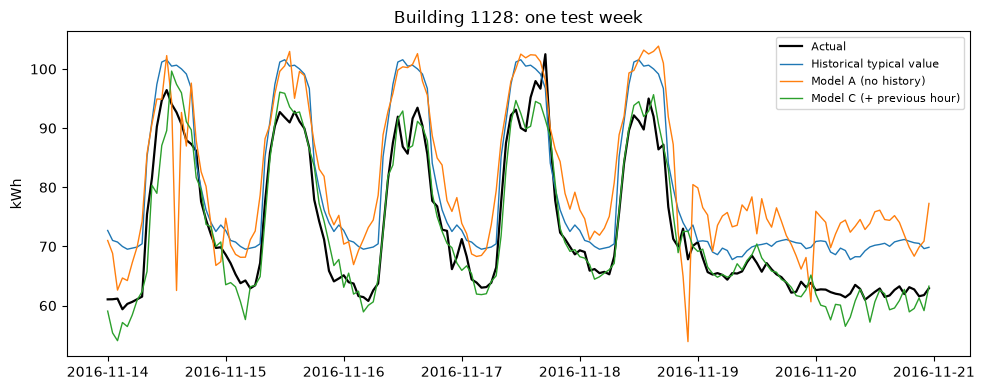

In [11]:
import matplotlib.pyplot as plt

b = df[df["split"] == "test"].groupby("building_id")["y"].mean().sort_values().index[len(id_set) // 2]
wk = df[(df["building_id"] == b) & (df["timestamp"] >= VAL_END + pd.Timedelta(days=7)) &
        (df["timestamp"] < VAL_END + pd.Timedelta(days=14))]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(wk["timestamp"], wk["y"], color="black", lw=1.6, label="Actual")
ax.plot(wk["timestamp"], wk["pred_typical"], lw=1, label="Historical typical value")
ax.plot(wk["timestamp"], wk["pred_A"], lw=1, label="Model A (no history)")
ax.plot(wk["timestamp"], wk["pred_C"], lw=1, label="Model C (+ previous hour)")
ax.set_title(f"Building {b}: one test week")
ax.set_ylabel("kWh")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "predictors_example_week.png", dpi=200)
plt.show()

## 11. Save the predictions

**What happens:** the file Part C reads. One row per building and hour with the original reading (kWh) and one column per predictor. Training rows are included (the model predictions there are in-sample), because Part C needs the training readings for the fixed-percentile method. The settings are saved so the run can be reproduced.

In [12]:
out = df[["building_id", "timestamp", "meter_reading", "split"] + pc].copy()
try:
    out.to_parquet(OUT_DIR / "predictions.parquet", index=False)
    print("saved predictions.parquet")
except Exception as e:
    print("parquet not available (", type(e).__name__, "), saving csv.gz instead")
    out.to_csv(OUT_DIR / "predictions.csv.gz", index=False)

with open(OUT_DIR / "predictor_settings.json", "w") as f:
    json.dump({"model_params": BEST, "features": FEATURES, "tuned": TUNE, "seed": SEED,
               "train_end": str(TRAIN_END), "val_end": str(VAL_END), "zero_run_hours": ZERO_RUN_HOURS}, f, indent=2)
print("rows:", len(out), "| columns:", list(out.columns))

saved predictions.parquet
rows: 1756800 | columns: ['building_id', 'timestamp', 'meter_reading', 'split', 'pred_last_hour', 'pred_typical', 'pred_A', 'pred_B', 'pred_C']


## What to write down for the report

- The split dates, and that the month is not used as a feature.
- That history is built by time and verified (the check in step 4).
- That the typical value and the model use training data only, and settings were picked on validation only.
- That A, B and C use identical settings and rows, differing only in features.
- The accuracy table (step 9), with the note that accuracy is not the project result.

**Next:** run Part C (cut-offs and flags), then Part D (evaluation). Part C reads `outputs/predictions.parquet` (or `.csv.gz`) and needs no changes if you keep the column names.